# Projet ADEME : Optimisation Multimodale Intelligente du Dernier Kilomètre

Auteurs : Hugo, Saad, Daoud, Ange Manuella

## Sommaire

* [1. Contexte et Définition du Problème](#section-1)
* [2. Étude théorique et complexité](#section-2)
* [3. Modélisation mathématique (PLNE)](#section-3)
    * [3.1. Paramètres](#section-3-1)
    * [3.2. Variables de décision](#section-3-2)
    * [3.3. Fonction objectif](#section-3-3)
    * [3.4. Contraintes](#section-3-4)
    * [3.5. Utilisation de l'approche exacte](#section-3-5)
* [4. Choix de la métaheuristique : ALNS avec recuit simulé](#section-4)
    * [4.1. Définition d'une solution](#section-4-1)
    * [4.2. Principe : détruire puis reconstruire](#section-4-2)
    * [4.3. Mécanismes de guidage](#section-4-3)
    * [4.4. Tester si une insertion est réalisable](#section-4-4)
    * [4.5. Complexité d'une itération](#section-4-5)
* [5. Implémentation](#section-5)
    * [5.0. Environnement et chargement des instances](#section-5-0)
    * [5.1. Données](#section-5-1)
    * [5.2. Coût et réalisabilité d'une tournée](#section-5-2)
    * [5.3. Insertion au meilleur endroit](#section-5-3)
    * [5.4. Méthodes de réparation](#section-5-4)
    * [5.5. Méthodes de destruction](#section-5-5)
    * [5.6. Choix adaptatif des méthodes](#section-5-6)
    * [5.7. Boucle principale](#section-5-7)
    * [5.8. Vérificateur](#section-5-8)
    * [5.9. Cas de test](#section-5-9)
    * [5.10. Démonstration](#section-5-10)
* [6. Étude expérimentale](#section-6)
    * [6.0. Plan d'expérience](#section-6-0)
    * [6.1. Comparaison avec le PLNE](#section-6-1)
    * [6.2. Instances de Solomon](#section-6-2)
    * [6.3. Convergence](#section-6-3)
    * [6.4. Passage à l'échelle](#section-6-4)
    * [6.5. Sensibilité aux paramètres](#section-6-5)
    * [6.6. Rôle des opérateurs de destruction](#section-6-6)
    * [6.7. Coût des fenêtres de temps](#section-6-7)
* [7. Limites et axes d'amélioration](#section-7)
* [8. Conclusion](#section-8)
* [9. Références](#section-9)

<a id="section-1"></a>
## 1. Contexte et Définition du Problème

Dans le cadre de l'appel à manifestation d'intérêt de l'ADEME, notre structure CesiCDP étudie la logistique du transport urbain. Optimiser les tournées de livraison permet de réduire les émissions de gaz à effet de serre et de mieux utiliser la flotte.

Pour rester proches des contraintes réelles des professionnels, nous avons choisi le niveau A : le CVRPTW (Capacitated Vehicle Routing Problem with Time Windows).

Une flotte de $K$ camions de même capacité $Q$ part d'un dépôt central pour livrer des clients. Chaque client a :
1. une demande (poids ou volume) ;
2. une fenêtre de temps $[e_i, l_i]$ pendant laquelle la livraison doit commencer ;
3. un temps de service sur place.

Un camion peut attendre sur place si la fenêtre n'est pas encore ouverte, mais il ne peut pas arriver en retard. L'objectif est de minimiser la distance totale parcourue par la flotte.

<a id="section-2"></a>
## 2. Étude théorique et complexité

Avant de choisir une méthode de résolution, nous étudions la complexité du problème.

Théorème : le CVRPTW (version optimisation) est NP-difficile.

Preuve par réduction. Le problème du voyageur de commerce (TSP) cherche le plus court cycle passant une fois par chaque ville. Sa version décision est NP-complète.

Prenons une instance du CVRPTW et imposons :
* un seul véhicule ($K = 1$) ;
* une capacité infinie ($Q = \infty$) ;
* des fenêtres de temps sans contrainte ($e_i = 0$ et $l_i = \infty$ pour tout client $i$) ;
* un temps de service nul.

On obtient exactement un TSP. Le TSP est donc un cas particulier du CVRPTW, qui est au moins aussi difficile : le CVRPTW est NP-difficile. Sauf si P = NP, il n'existe pas d'algorithme exact polynomial pour le résoudre. En pratique, le temps de résolution exacte augmente très vite avec le nombre de clients. C'est pour cela que nous utilisons une métaheuristique.

<a id="section-3"></a>
## 3. Modélisation mathématique (PLNE)

Nous utilisons une formulation classique du VRPTW à deux indices.

<a id="section-3-1"></a>
### 3.1. Paramètres
* $N = \{1, ..., n\}$ : ensemble des clients.
* $V = \{0\} \cup N \cup \{n+1\}$ : ensemble des nœuds. $0$ est le dépôt de départ et $n+1$ le dépôt d'arrivée (même lieu physique).
* $A = \{(i,j) \in V^2 : i \neq j,\ i \neq n+1,\ j \neq 0\}$ : arcs utilisables. On ne revient jamais au dépôt de départ et on ne repart jamais du dépôt d'arrivée.
* $K$ : nombre de camions.
* $Q$ : capacité d'un camion.
* $q_i$ : demande du client $i$ ($q_0 = q_{n+1} = 0$).
* $c_{ij}$ et $t_{ij}$ : distance et temps de trajet de l'arc $(i, j)$. Sur les instances de Solomon, $c_{ij} = t_{ij}$ = distance euclidienne.
* $[e_i, l_i]$ : fenêtre de temps du nœud $i$ ($[e_0, l_0]$ correspond aux horaires du dépôt).
* $s_i$ : temps de service au nœud $i$ ($s_0 = 0$).
* $M_{ij} = \max(0,\ l_i + s_i + t_{ij} - e_j)$ : constante « Big-M » de l'arc $(i,j)$. C'est la plus petite valeur qui désactive la contrainte de temps quand l'arc n'est pas utilisé. Un $M$ trop grand affaiblit la relaxation linéaire.

<a id="section-3-2"></a>
### 3.2. Variables de décision
* $x_{ij} \in \{0, 1\}$ : vaut 1 si un camion emprunte l'arc $(i,j) \in A$, 0 sinon.
* $w_i \ge 0$ : heure de début de service au nœud $i$.
* $u_i \ge 0$ : charge du camion après la visite de $i$.

<a id="section-3-3"></a>
### 3.3. Fonction objectif
On minimise la distance totale :
$$ \text{Min} \sum_{(i,j) \in A} c_{ij} x_{ij} $$

Dans la littérature, l'objectif sur les instances de Solomon est souvent hiérarchique : d'abord le nombre de véhicules, puis la distance. Nous gardons la distance seule, car c'est l'objectif des meilleures solutions connues fournies par CVRPLIB et vrplib. C'est ce qui permet de calculer un gap comparable.

<a id="section-3-4"></a>
### 3.4. Contraintes

Routage :
1. Chaque client est quitté une fois : $\sum_{j : (i,j) \in A} x_{ij} = 1 \quad \forall i \in N$
2. Conservation du flot : $\sum_{i : (i,h) \in A} x_{ih} - \sum_{j : (h,j) \in A} x_{hj} = 0 \quad \forall h \in N$
3. Au plus $K$ camions partent du dépôt : $\sum_{j \in N} x_{0j} \le K$. Avec (2), autant de camions arrivent en $n+1$.

Capacité :

4. Suivi de la charge : $u_i + q_j \le u_j + Q(1 - x_{ij}) \quad \forall (i,j) \in A,\ i, j \in N$
5. Respect de la capacité : $q_i \le u_i \le Q \quad \forall i \in N$

Fenêtres de temps :

6. Continuité du temps : $w_i + s_i + t_{ij} \le w_j + M_{ij}(1 - x_{ij}) \quad \forall (i,j) \in A$
7. Respect de la fenêtre : $e_i \le w_i \le l_i \quad \forall i \in V$

Domaines : $x_{ij} \in \{0,1\}$, $w_i \ge 0$, $u_i \ge 0$.

Remarques :
* L'attente est possible car (6) est une inégalité : $w_j$ peut être plus grand que l'heure d'arrivée, tant que $w_j \ge e_j$ (7). Le retard est interdit par $w_j \le l_j$.
* Les contraintes (4) et (6) éliminent chacune les sous-tours, car la charge et l'heure augmentent strictement le long d'un chemin.
* Prétraitement : un arc tel que $e_i + s_i + t_{ij} > l_j$ ne peut jamais être utilisé, on le retire de $A$. Sur les instances à fenêtres serrées, cela enlève beaucoup d'arcs.
* Par rapport à la première version, nous avons défini l'ensemble $A$ explicitement, calculé un Big-M par arc ($M_{ij}$ pour le temps, $Q$ pour la charge) et indexé la contrainte (1) sur les arcs existants.

<a id="section-3-5"></a>
### 3.5. Utilisation de l'approche exacte
Le PLNE est codé plus bas et résolu avec le solveur HiGHS, inclus dans scipy.optimize.milp. Comme le problème est NP-difficile, nous ne l'utilisons pas sur les instances complètes. Il sert de référence (optimum prouvé ou borne inférieure) sur de petites sous-instances, pour vérifier la métaheuristique (section 6.1).

### <a id="section-4"></a>
## 4. Choix de la métaheuristique : ALNS avec recuit simulé

Le problème étant NP-difficile, nous utilisons une métaheuristique. Un recuit simulé classique ne déplace qu'un client à la fois (relocate, swap). Avec des fenêtres de temps serrées, la plupart de ces petits mouvements rendent la tournée irréalisable et la recherche n'avance plus. Nous gardons le recuit simulé comme règle d'acceptation, mais nous l'appliquons à de grands voisinages. Cette méthode s'appelle l'ALNS (Adaptive Large Neighbourhood Search) et elle est très utilisée pour le VRPTW.

<a id="section-4-1"></a>
### 4.1. Définition d'une solution
Une solution est une liste de tournées. Chaque tournée est la liste des clients dans l'ordre de visite, par exemple [ [5, 12, 3], [7, 1] ]. Le départ et le retour au dépôt 0 ne sont pas écrits. On utilise au plus $K$ tournées. Toutes les solutions manipulées sont réalisables : la capacité et les fenêtres de temps sont toujours respectées. Le coût d'une solution est sa distance totale.

<a id="section-4-2"></a>
### 4.2. Principe : détruire puis reconstruire
On construit une solution initiale, puis on répète un grand nombre de fois :
1. Destruction : on retire $q$ clients de la solution courante, avec $q$ tiré entre 5 et 20.
2. Réparation : on réinsère ces clients un par un à la meilleure position possible.
3. Acceptation : on décide avec le recuit simulé si la nouvelle solution remplace la solution courante.

À la fin, on renvoie la meilleure solution trouvée.

```text
solution  = construire_solution_initiale()
meilleure = solution
T = T0
répéter N fois :
    candidate = copie(solution)
    d = choisir une destruction (selon les poids)
    r = choisir une réparation (selon les poids)
    retires = d(candidate, q)
    r(candidate, retires)
    delta = cout(candidate) - cout(solution)
    si cout(candidate) < cout(meilleure) : meilleure = candidate
    si delta < 0 ou hasard() < exp(-delta / T) : solution = candidate
    mettre à jour les scores de d et r
    T = alpha * T
renvoyer meilleure
```

Méthodes de destruction :

| Méthode | Idée | Rôle |
|---|---|---|
| Aleatoire | $q$ clients au hasard | diversification |
| Pire | les clients qui font les plus gros détours, avec un peu de hasard | intensification |
| Voisins | un client au hasard et ses $q-1$ plus proches voisins | réorganiser des clients proches entre eux |

Méthodes de réparation :

| Méthode | Idée |
|---|---|
| Gloutonne | à chaque étape, on insère le client dont la meilleure insertion coûte le moins |
| Regret (regret-2) | on insère d'abord le client pour qui l'écart entre la meilleure et la deuxième meilleure tournée est le plus grand, pour ne pas le laisser sans place à la fin |

<a id="section-4-3"></a>
### 4.3. Mécanismes de guidage
* Adaptation : chaque méthode a un poids $\omega$ et elle est tirée au sort proportionnellement à ce poids. Elle gagne 33 points si elle donne une nouvelle meilleure solution, 9 si elle améliore la solution courante et 13 si une solution moins bonne est acceptée. Toutes les 100 itérations, $\omega \leftarrow (1-\rho)\,\omega + \rho \times \text{score moyen}$, avec $\rho = 0.1$.
* Recuit simulé : une solution moins bonne de $\Delta$ est acceptée avec la probabilité $P = \exp(-\Delta / T)$. Au début $T$ est grand et on accepte souvent des solutions moins bonnes, ce qui permet d'explorer. À la fin $T$ est petit et on n'accepte presque plus que des améliorations. On choisit $T_0$ pour qu'une solution 5 % plus chère que la solution initiale soit acceptée une fois sur deux : $T_0 = 0.05\,C_0 / \ln 2$. La température diminue de façon géométrique ($T \leftarrow \alpha T$) jusqu'à $T_0 / 1000$.
* Critère d'arrêt : un nombre fixe d'itérations, pour que les expériences soient reproductibles.

<a id="section-4-4"></a>
### 4.4. Tester si une insertion est réalisable
Pour savoir si un client peut être inséré à une position, on simule le camion sur la nouvelle tournée. Il roule, attend s'il arrive avant $e_i$, et la tournée est refusée s'il arrive après $l_i$ ou si la charge dépasse $Q$. Ce sont les contraintes (5) à (7) du PLNE, vérifiées client par client. Ce test coûte $O(|r|)$, où $|r|$ est la longueur de la tournée.

<a id="section-4-5"></a>
### 4.5. Complexité d'une itération
Avec $n$ clients et $q$ clients retirés, la destruction coûte au plus $O(n \log n)$ à cause du tri. La réparation réinsère les $q$ clients : à chaque étape, elle teste pour chaque client restant (au plus $q$) toutes les positions (environ $n$), chaque test coûtant $O(|r|)$. Une itération coûte donc $O(q^2 \cdot n \cdot |r|)$, et c'est la réparation qui prend le plus de temps.

Nous avons choisi un code simple en Python : listes, simulation complète de la tournée et copie de la solution à chaque itération. Une version plus rapide est possible avec un test d'insertion en $O(1)$ et la compilation Numba, mais elle est beaucoup plus difficile à lire (voir section 7).

<a id="section-5"></a>
## 5. Implémentation

Le code est découpé en petites fonctions. Le schéma ci-dessous montre comment elles s'appellent entre elles.

```text
load_instance -> build_data -> d (données de l'instance)
                                 |
alns(d)
 |-- reparation_gloutonne          construction de la solution initiale
 |-- à chaque itération :
 |     choisir                     tirage d'une destruction et d'une réparation
 |     destruction_xxx -> retirer  on enlève q clients
 |     reparation_xxx              on les remet
 |        -> positions_possibles -> tournee_realisable
 |        -> inserer
 |     cout_solution, recuit       on garde ou non la nouvelle solution
 |     mettre_a_jour               mise à jour des poids
 '-- renvoie la meilleure solution
                                 |
check_solution                     vérification et recalcul du coût
                                 |
run_benchmark -> cached            répétition sur plusieurs instances, résultats en CSV
```

<a id="section-5-0"></a>
### 5.0. Environnement et chargement des instances

Depuis la version 2.0 de `vrplib`, les fonctions `download_instance` et `download_solution` n'existent plus, car l'ancien serveur CVRPLIB a fermé. Seules `read_instance` et `read_solution` restent, et elles lisent des fichiers locaux. Nous téléchargeons donc une fois les instances de Solomon et leurs meilleures solutions connues (BKS) depuis le dépôt [PyVRP/Instances](https://github.com/PyVRP/Instances), dans le dossier `instances/solomon/`.

Convention de distance : les BKS de ce dépôt utilisent la convention DIMACS, avec des distances tronquées à une décimale ($\lfloor 10\,d \rfloor / 10$). Nous faisons de même, sinon le coût optimal de C101 serait 828,94 au lieu de 827,3 et les gaps seraient faux.

In [1]:
import math
import os
import random
import time
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import vrplib
from scipy import stats
from scipy.optimize import milp, LinearConstraint, Bounds
from scipy.sparse import lil_matrix

INST_DIR = os.path.join("instances", "solomon")
RES_DIR = "resultats"
os.makedirs(INST_DIR, exist_ok=True)
os.makedirs(RES_DIR, exist_ok=True)
GITHUB = "https://raw.githubusercontent.com/PyVRP/Instances/main/VRPTW/Solomon"


def load_instance(name):
    """Télécharge (si besoin) puis lit une instance de Solomon et sa meilleure solution connue (BKS)."""
    paths = {}
    for ext in ("vrp", "sol"):
        paths[ext] = os.path.join(INST_DIR, f"{name}.{ext}")
        if not os.path.exists(paths[ext]):
            urllib.request.urlretrieve(f"{GITHUB}/{name}.{ext}", paths[ext])
    return vrplib.read_instance(paths["vrp"]), vrplib.read_solution(paths["sol"])


def family(name):
    """C101 -> C1, RC201 -> RC2."""
    return name[:-2]


SOLOMON = ([f"C1{i:02d}" for i in range(1, 10)] + [f"C2{i:02d}" for i in range(1, 9)]
           + [f"R1{i:02d}" for i in range(1, 13)] + [f"R2{i:02d}" for i in range(1, 12)]
           + [f"RC1{i:02d}" for i in range(1, 9)] + [f"RC2{i:02d}" for i in range(1, 9)])
print(len(SOLOMON), "instances de Solomon")

56 instances de Solomon


<a id="section-5-1"></a>
### 5.1. Données
La fonction `build_data` range une instance dans un dictionnaire `d` qui contient des listes Python : distances (qui servent aussi de temps de trajet), demandes, fenêtres $[e_i, l_i]$, temps de service, capacité $Q$ et nombre de camions $K$. Le nœud 0 est le dépôt et les nœuds $1$ à $n$ sont les clients.

In [2]:
def build_data(instance):
    """Range une instance vrplib dans un dictionnaire de listes Python simples.
    Nœud 0 = dépôt, nœuds 1..n = clients. Temps de trajet = distance."""
    coords = np.asarray(instance["node_coord"], dtype=float)
    nb = len(coords)
    dist = [[math.floor(10 * math.dist(coords[i], coords[j])) / 10   # convention DIMACS
             for j in range(nb)] for i in range(nb)]
    tw = instance["time_window"]
    service = instance.get("service_time", 0)
    if np.isscalar(service):                 # certains fichiers donnent une seule valeur
        service = [float(service)] * nb
    service = [float(x) for x in service]
    service[0] = 0.0                         # pas de service au dépôt
    return dict(
        n=nb - 1,                            # nombre de clients
        K=int(instance["vehicles"]),         # nombre de camions disponibles
        Q=float(instance["capacity"]),       # capacité d'un camion
        coords=coords,                       # (pour les graphiques uniquement)
        dist=dist,
        demande=[float(x) for x in instance["demand"]],
        debut=[float(x) for x in tw[:, 0]],  # e_i : ouverture de la fenêtre
        fin=[float(x) for x in tw[:, 1]],    # l_i : fermeture de la fenêtre
        service=service,                     # s_i : temps passé chez le client
    )

<a id="section-5-2"></a>
### 5.2. Coût et réalisabilité d'une tournée
La fonction `tournee_realisable` simule le camion le long de la tournée (section 4.4). Elle renvoie faux si le camion est trop chargé ou s'il arrive après la fermeture d'une fenêtre.

In [3]:
# Une tournée = liste des clients dans l'ordre de visite, ex. [5, 12, 3].
# Le dépôt (0) n'est pas écrit : on part de 0 et on revient à 0 implicitement.
# Une solution = liste de tournées.

def cout_tournee(tournee, d):
    """Distance totale parcourue : 0 -> clients -> 0."""
    chemin = [0] + tournee + [0]
    return sum(d["dist"][chemin[k]][chemin[k + 1]] for k in range(len(chemin) - 1))


def cout_solution(solution, d):
    return sum(cout_tournee(t, d) for t in solution)


def tournee_realisable(tournee, d):
    """Simule le camion le long de la tournée et vérifie capacité + fenêtres de temps."""
    if sum(d["demande"][c] for c in tournee) > d["Q"]:
        return False                         # camion trop chargé
    heure, position = 0.0, 0                 # on part du dépôt à l'heure 0
    for c in tournee:
        heure += d["service"][position] + d["dist"][position][c]   # service précédent + trajet
        if heure > d["fin"][c]:
            return False                     # arrivé après la fermeture : interdit
        heure = max(heure, d["debut"][c])    # arrivé trop tôt : on attend
        position = c
    heure += d["service"][position] + d["dist"][position][0]       # retour au dépôt
    return heure <= d["fin"][0]              # le dépôt a aussi une heure de fermeture

<a id="section-5-3"></a>
### 5.3. Insertion au meilleur endroit
Insérer le client $c$ entre $a$ et $b$ coûte $d_{ac} + d_{cb} - d_{ab}$, c'est le détour. La fonction `positions_possibles` teste toutes les positions de toutes les tournées et garde celles qui sont réalisables. S'il reste un camion libre, on peut aussi ouvrir une nouvelle tournée.

In [4]:
def positions_possibles(client, solution, d):
    """Liste de toutes les insertions réalisables : (surcoût, numéro de tournée, position).
    Numéro de tournée = len(solution) signifie « ouvrir un nouveau camion »."""
    D = d["dist"]
    options = []
    for r, tournee in enumerate(solution):
        if sum(d["demande"][c] for c in tournee) + d["demande"][client] > d["Q"]:
            continue                         # camion déjà trop plein : inutile de tester
        chemin = [0] + tournee + [0]
        for p in range(len(tournee) + 1):    # insertion entre chemin[p] et chemin[p+1]
            a, b = chemin[p], chemin[p + 1]
            surcout = D[a][client] + D[client][b] - D[a][b]
            if tournee_realisable(tournee[:p] + [client] + tournee[p:], d):
                options.append((surcout, r, p))
    if len(solution) < d["K"]:               # il reste un camion libre
        options.append((D[0][client] + D[client][0], len(solution), 0))
    return options


def inserer(client, r, p, solution):
    if r == len(solution):
        solution.append([client])            # nouveau camion
    else:
        solution[r].insert(p, client)

<a id="section-5-4"></a>
### 5.4. Méthodes de réparation
Réparation gloutonne et regret-2 (section 4.2). Si un client ne peut être placé nulle part, la réparation échoue et l'itération est rejetée.

In [5]:
def reparation_gloutonne(solution, retires, d):
    """À chaque étape, insère le client dont l'insertion coûte le moins cher."""
    while retires:
        meilleur = None
        for c in retires:
            options = positions_possibles(c, solution, d)
            if not options:
                return False                 # un client ne rentre nulle part : échec
            o = min(options)
            if meilleur is None or o[0] < meilleur[0]:
                meilleur = (o[0], c, o[1], o[2])
        _, c, r, p = meilleur
        inserer(c, r, p, solution)
        retires.remove(c)
    return True


def reparation_regret(solution, retires, d):
    """Regret-2 : insère d'abord le client qui « perdrait le plus » s'il ne prenait pas
    sa meilleure tournée (écart entre sa 2e meilleure et sa meilleure tournée)."""
    while retires:
        choix = None
        for c in retires:
            options = positions_possibles(c, solution, d)
            if not options:
                return False
            par_tournee = {}                 # meilleur surcoût dans chaque tournée
            for surcout, r, p in options:
                if r not in par_tournee or surcout < par_tournee[r][0]:
                    par_tournee[r] = (surcout, r, p)
            tries = sorted(par_tournee.values())
            regret = tries[1][0] - tries[0][0] if len(tries) > 1 else float("inf")
            if choix is None or regret > choix[0]:
                choix = (regret, c, tries[0][1], tries[0][2])
        _, c, r, p = choix
        inserer(c, r, p, solution)
        retires.remove(c)
    return True

<a id="section-5-5"></a>
### 5.5. Méthodes de destruction
Destruction aléatoire, pire et voisins (section 4.2). Les tournées qui deviennent vides sont supprimées.

In [6]:
def retirer(clients, solution):
    for t in solution:
        t[:] = [c for c in t if c not in clients]
    solution[:] = [t for t in solution if t]  # on supprime les camions vides


def destruction_aleatoire(solution, q, d):
    """Retire q clients au hasard : diversifie la recherche."""
    tous = [c for t in solution for c in t]
    clients = random.sample(tous, q)
    retirer(clients, solution)
    return clients


def destruction_pire(solution, q, d):
    """Retire des clients qui provoquent les plus gros détours."""
    D = d["dist"]
    gains = []
    for t in solution:
        chemin = [0] + t + [0]
        for k in range(1, len(chemin) - 1):
            a, c, b = chemin[k - 1], chemin[k], chemin[k + 1]
            gains.append((D[a][c] + D[c][b] - D[a][b], c))
    gains.sort(reverse=True)
    candidats = [c for _, c in gains[:2 * q]]  # un peu de hasard : on pioche parmi les 2q pires
    clients = random.sample(candidats, q)
    retirer(clients, solution)
    return clients


def destruction_voisins(solution, q, d):
    """Retire un client au hasard + ses q-1 plus proches voisins : ils pourront être
    réorganisés ensemble (idée de Shaw, en version simplifiée)."""
    tous = [c for t in solution for c in t]
    graine = random.choice(tous)
    tous.sort(key=lambda c: d["dist"][graine][c])
    clients = tous[:q]                       # la graine elle-même est à distance 0
    retirer(clients, solution)
    return clients

<a id="section-5-6"></a>
### 5.6. Choix adaptatif des méthodes
Tirage proportionnel aux poids, puis mise à jour des poids toutes les 100 itérations (section 4.3).

In [7]:
def choisir(poids):
    """Roulette : une méthode est tirée avec une probabilité proportionnelle à son poids."""
    return random.choices(range(len(poids)), weights=poids)[0]


def mettre_a_jour(poids, scores, utilisations, reaction):
    """Fin d'un segment : chaque poids se rapproche du score moyen obtenu par la méthode."""
    for i in range(len(poids)):
        if utilisations[i] > 0:
            poids[i] = (1 - reaction) * poids[i] + reaction * scores[i] / utilisations[i]
        scores[i], utilisations[i] = 0, 0

<a id="section-5-7"></a>
### 5.7. Boucle principale
La fonction `alns` suit le pseudo-code de la section 4.2. On construit la solution initiale en insérant tous les clients avec la réparation gloutonne, puis on calcule $T_0$. À chaque itération, on choisit les méthodes et $q$, on détruit et on répare une copie de la solution courante, puis on applique le recuit simulé et on met à jour les scores. L'historique des coûts est gardé pour tracer les courbes de convergence.

In [8]:
DESTRUCTIONS = [destruction_aleatoire, destruction_pire, destruction_voisins]
REPARATIONS = [reparation_gloutonne, reparation_regret]
NOMS_D = ["aleatoire", "pire", "voisins"]
NOMS_R = ["gloutonne", "regret"]


def alns(d, iterations=2000, q_min=5, q_max=20, depart_pire=0.05, reaction=0.1,
         segment=100, graine=0):
    """ALNS + recuit simulé. Renvoie un dictionnaire de résultats."""
    random.seed(graine)
    t_debut = time.perf_counter()
    q_min, q_max = min(q_min, d["n"]), min(q_max, d["n"])

    # 1) Solution initiale : réparation gloutonne à partir d'une solution vide
    solution = []
    if not reparation_gloutonne(solution, list(range(1, d["n"] + 1)), d):
        raise ValueError("Pas de solution initiale réalisable avec K camions")
    cout = cout_solution(solution, d)
    cout_initial = cout
    meilleure, meilleur_cout = [t[:] for t in solution], cout

    # 2) Recuit : T0 tel qu'une solution `depart_pire` (5 %) plus chère soit acceptée 1 fois sur 2
    T = depart_pire * cout / math.log(2)
    alpha = (1 / 1000) ** (1 / iterations)   # T finit à T0 / 1000

    poids_d, poids_r = [1.0] * 3, [1.0] * 2
    scores_d, scores_r, util_d, util_r = [0] * 3, [0] * 2, [0] * 3, [0] * 2
    records_d, total_d = [0] * 3, [0] * 3    # statistiques pour l'étude des opérateurs
    hist_courant, hist_meilleur = [], []

    for it in range(1, iterations + 1):
        # 3) Choix des méthodes et de q
        i_d, i_r = choisir(poids_d), choisir(poids_r)
        q = random.randint(q_min, q_max)

        # 4) Détruire puis réparer une COPIE de la solution courante
        candidate = [t[:] for t in solution]
        retires = DESTRUCTIONS[i_d](candidate, q, d)
        ok = REPARATIONS[i_r](candidate, retires, d)

        # 5) Acceptation (recuit simulé) et points
        points = 0
        if ok:
            c = cout_solution(candidate, d)
            delta = c - cout
            if c < meilleur_cout - 1e-9:         # nouveau record
                meilleure, meilleur_cout = [t[:] for t in candidate], c
                points = 33
                records_d[i_d] += 1
            elif delta < -1e-9:                  # mieux que la solution courante
                points = 9
            if delta < 0 or random.random() < math.exp(-delta / T):
                solution, cout = candidate, c
                if points == 0 and delta > 1e-9:
                    points = 13                  # acceptée bien que pire

        # 6) Mise à jour des scores, puis des poids tous les `segment` itérations
        scores_d[i_d] += points; util_d[i_d] += 1; total_d[i_d] += 1
        scores_r[i_r] += points; util_r[i_r] += 1
        if it % segment == 0:
            mettre_a_jour(poids_d, scores_d, util_d, reaction)
            mettre_a_jour(poids_r, scores_r, util_r, reaction)
        T *= alpha
        hist_courant.append(cout)
        hist_meilleur.append(meilleur_cout)

    return dict(tournees=meilleure, cout=meilleur_cout, cout_initial=cout_initial,
                temps=time.perf_counter() - t_debut, hist_courant=hist_courant,
                hist_meilleur=hist_meilleur, poids_d=poids_d, poids_r=poids_r,
                records_d=records_d, total_d=total_d)

<a id="section-5-8"></a>
### 5.8. Vérificateur
La fonction `check_solution` recalcule tout sans utiliser le code du solveur : chaque client est visité une seule fois, il n'y a pas plus de $K$ camions, et la capacité et les fenêtres sont respectées. Nous l'appelons sur toutes les solutions de l'étude expérimentale.

In [9]:
def check_solution(d, tournees):
    """Vérification indépendante : chaque client une fois, flotte, capacité, fenêtres.
    Renvoie le coût recalculé."""
    visites = sorted(c for t in tournees for c in t)
    assert visites == list(range(1, d["n"] + 1)), "chaque client doit être visité une fois"
    assert len(tournees) <= d["K"], "trop de camions"
    total = 0.0
    for t in tournees:                       # recalcul complet, sans réutiliser le code du solveur
        assert sum(d["demande"][c] for c in t) <= d["Q"], f"capacité dépassée : {t}"
        heure, prec = d["debut"][0], 0
        for c in list(t) + [0]:
            heure = max(d["debut"][c], heure + d["service"][prec] + d["dist"][prec][c])
            assert heure <= d["fin"][c], f"fenêtre violée au nœud {c}"
            total += d["dist"][prec][c]
            prec = c
    return total

<a id="section-5-9"></a>
### 5.9. Cas de test
Nous testons d'abord une petite instance construite à la main dont nous connaissons la solution optimale. Nous vérifions ensuite que le vérificateur rejette une solution qui viole une fenêtre ou la capacité.

L'instance contient un dépôt en (0, 0) et quatre clients aux coins d'un carré : 1 en (10, 10), 2 en (-10, 10), 3 en (-10, -10) et 4 en (10, -10). Chaque client demande 10 et la capacité est de 20, donc un camion sert au plus deux clients et il faut au moins deux tournées. Le client 1 doit être livré avant 20 et le client 3 entre 200 et 300.

La distance du dépôt à un coin vaut $\sqrt{200} = 14{,}14$, soit 14,1 après troncature, et deux coins voisins sont à 20. La meilleure solution relie deux coins voisins dans chaque tournée, par exemple `[[1, 2], [4, 3]]`, pour un coût de $2 \times (14{,}1 + 20 + 14{,}1) = 96{,}4$. Dans la tournée `[4, 3]`, le camion arrive en 3 vers $t = 39$ et attend l'ouverture à 200, ce qui est autorisé.

Les deux solutions invalides testées ensuite sont :
* `[[3, 1], [2, 4]]` : le camion attend en 3 jusqu'à 200, puis arrive en 1 bien après la fermeture à 20 ;
* `[[1, 2, 3], [4]]` : la première tournée transporte 30, plus que la capacité de 20.

In [10]:
def toy_instance():
    """Dépôt au centre, 4 clients aux 4 coins d'un carré de côté 20. Q = 20, chaque demande = 10.
    Les fenêtres imposent l'ordre : client 1 tôt, client 3 tard."""
    return dict(node_coord=np.array([[0, 0], [10, 10], [-10, 10], [-10, -10], [10, -10]]),
                demand=np.array([0, 10, 10, 10, 10]), capacity=20, vehicles=4,
                time_window=np.array([[0, 1000], [0, 20], [0, 1000], [200, 300], [0, 1000]]),
                service_time=5)


toy = build_data(toy_instance())
res = alns(toy, iterations=200, graine=0)
cost = check_solution(toy, res["tournees"])
print("tournées :", res["tournees"], "| coût :", round(cost, 1))

# 1) capacité 20 et demandes de 10 => 2 tournées de 2 clients
assert len(res["tournees"]) == 2 and all(len(t) == 2 for t in res["tournees"])
# 2) optimum = 2 tournées (dépôt -> coin -> coin adjacent -> dépôt) = 2 * (14.1 + 20 + 14.1)
assert abs(cost - 2 * (14.1 + 20 + 14.1)) < 1e-6
# 3) tests négatifs : le vérificateur doit rejeter une solution invalide
for mauvaise, msg in [([[3, 1], [2, 4]], "fenêtre"), ([[1, 2, 3], [4]], "capacité")]:
    try:
        check_solution(toy, mauvaise)
        raise RuntimeError("le vérificateur aurait dû rejeter cette solution")
    except AssertionError as err:
        print(f"solution invalide ({msg}) correctement rejetée :", err)
print("Tous les tests passent.")

tournées : [[1, 2], [4, 3]] | coût : 96.4
solution invalide (fenêtre) correctement rejetée : fenêtre violée au nœud 1
solution invalide (capacité) correctement rejetée : capacité dépassée : [1, 2, 3]
Tous les tests passent.


<a id="section-5-10"></a>
### 5.10. Démonstration
Résolution de R101 (100 clients dispersés, fenêtres serrées) et RC201 (clients en partie groupés, fenêtres larges) avec 2000 itérations.

R101: coût = 1656.9 | BKS = 1637.7 | gap = 1.17 % | camions = 20 (BKS : 20) | temps = 30 s | solution initiale = 2121.9


RC201: coût = 1298.2 | BKS = 1261.8 | gap = 2.88 % | camions = 8 (BKS : 9) | temps = 47 s | solution initiale = 1979.0


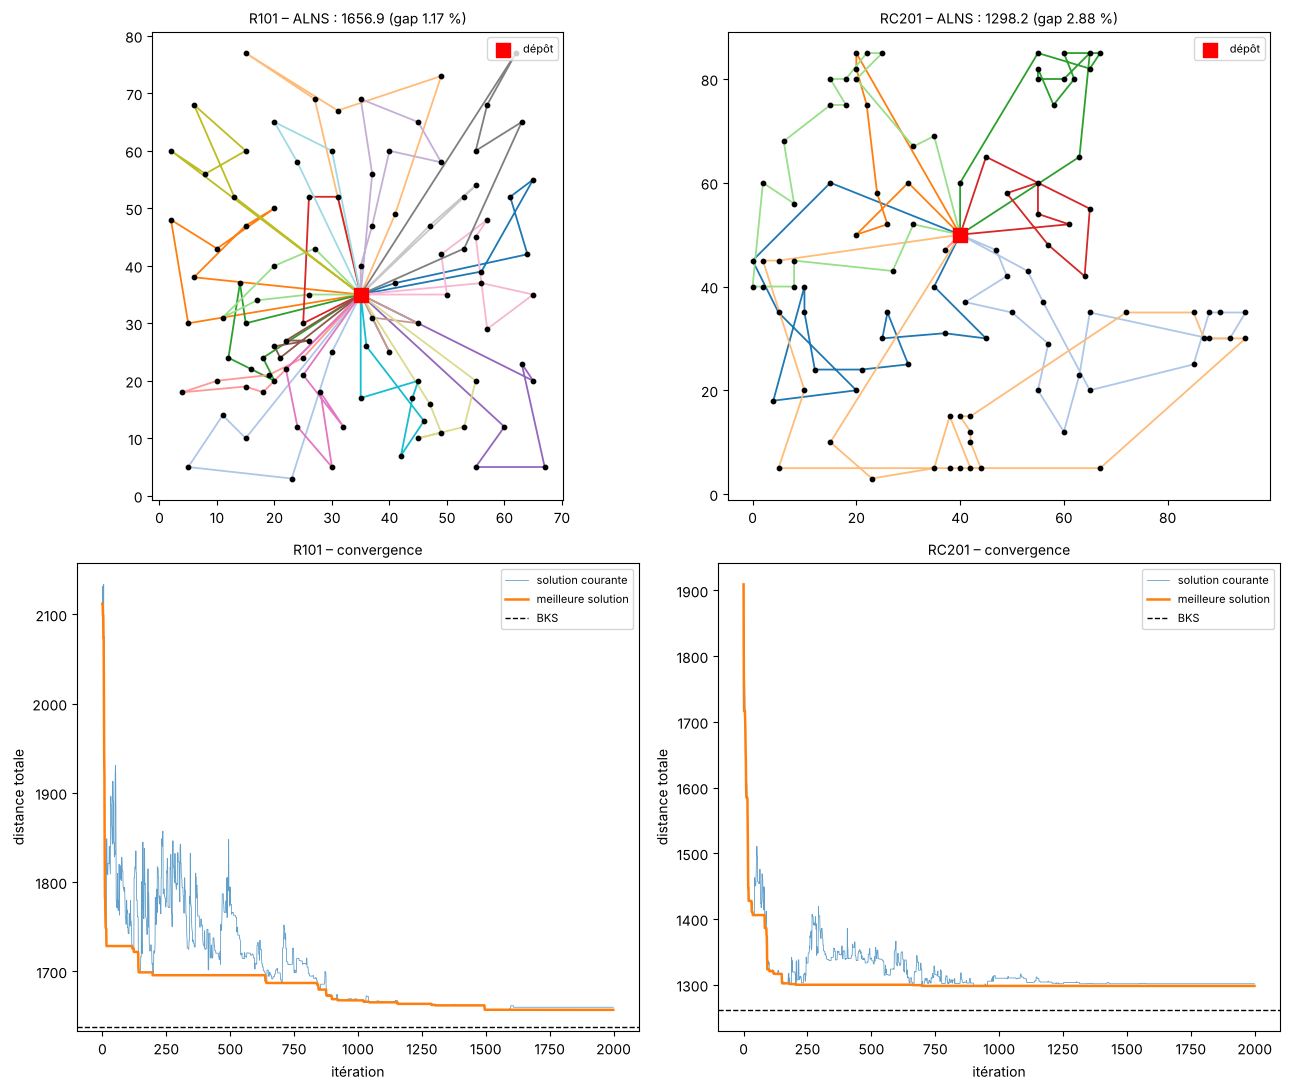

In [11]:
def plot_solution(d, tournees, title, ax):
    xy = d["coords"]
    cmap = plt.get_cmap("tab20")
    for k, t in enumerate(tournees):
        chemin = [0] + list(t) + [0]
        ax.plot(xy[chemin, 0], xy[chemin, 1], "-", lw=1.3, color=cmap(k % 20))
    ax.scatter(xy[1:, 0], xy[1:, 1], s=10, c="k", zorder=3)
    ax.scatter(xy[0, 0], xy[0, 1], marker="s", s=90, c="red", zorder=4, label="dépôt")
    ax.set_title(title, fontsize=10)
    ax.set_aspect("equal")
    ax.legend(loc="upper right", fontsize=8)


fig, axes = plt.subplots(2, 2, figsize=(13, 11))
for col, name in enumerate(["R101", "RC201"]):
    inst, bks = load_instance(name)
    d = build_data(inst)
    res = alns(d, iterations=2000, graine=1)
    cost = check_solution(d, res["tournees"])
    gap = 100 * (cost - bks["cost"]) / bks["cost"]
    print(f"{name}: coût = {cost:.1f} | BKS = {bks['cost']} | gap = {gap:.2f} % | "
          f"camions = {len(res['tournees'])} (BKS : {len(bks['routes'])}) | "
          f"temps = {res['temps']:.0f} s | solution initiale = {res['cout_initial']:.1f}")
    plot_solution(d, res["tournees"], f"{name} – ALNS : {cost:.1f} (gap {gap:.2f} %)", axes[0, col])
    ax = axes[1, col]
    ax.plot(res["hist_courant"], lw=0.6, alpha=0.7, label="solution courante")
    ax.plot(res["hist_meilleur"], lw=1.8, label="meilleure solution")
    ax.axhline(bks["cost"], color="k", ls="--", lw=1, label="BKS")
    ax.set_xlabel("itération")
    ax.set_ylabel("distance totale")
    ax.set_title(f"{name} – convergence", fontsize=10)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

Analyse : sur R101, l'ALNS trouve une solution à 1,17 % de la meilleure solution connue, avec le même nombre de camions (20), en 30 s. Sur RC201, l'écart est de 2,88 % avec 8 camions au lieu de 9. Dans les deux cas, la solution initiale gloutonne est loin de l'optimum (2121,9 et 1979,0) et l'ALNS la réduit de 22 % et 34 %.

Les courbes de convergence montrent deux phases. Au début, la température est élevée : la solution courante accepte souvent des dégradations et oscille beaucoup. Ensuite la température baisse, la solution courante se rapproche de la meilleure solution et les améliorations deviennent rares. La plus grande partie du gain est obtenue pendant les 500 premières itérations.

<a id="section-6"></a>
## 6. Étude expérimentale

<a id="section-6-0"></a>
### 6.0. Plan d'expérience

| # | Question | Instances | Facteur étudié | Répétitions |
|---|---|---|---|---|
| 6.1 | L'ALNS trouve-t-il l'optimum quand on le connaît ? | sous-instances de Solomon (10, 25, 50 clients) | méthode exacte ou heuristique | 1 |
| 6.2 | Qualité par rapport aux BKS | 56 instances de Solomon (6 familles) | répartition (C, R, RC) et horizon (1 = serré, 2 = large) | 1 graine |
| 6.3 | Convergence | R101, RC201 | nombre d'itérations | 3 graines |
| 6.4 | Passage à l'échelle | instances générées de 25 à 400 clients | taille $n$ | 1 |
| 6.5 | Sensibilité aux paramètres | une instance par famille | $q_{max}$, recuit, adaptation | 2 graines |
| 6.6 | Rôle des opérateurs | résultats de 6.2 | méthode de destruction | – |
| 6.7 | Coût des fenêtres de temps | 6 instances de Solomon | avec ou sans fenêtres | 1 |

Les instances de Solomon. Ce jeu de 56 instances a été publié par Solomon en 1987 et sert de référence pour comparer les méthodes de résolution du VRPTW. Chaque instance contient un dépôt et 100 clients placés sur une grille de 100 sur 100. Le fichier `.vrp` donne le nombre de camions, la capacité, le temps de service, puis pour chaque nœud ses coordonnées, sa demande et sa fenêtre de temps. Le premier nœud est le dépôt, et sa fenêtre donne l'heure à laquelle tous les camions doivent être rentrés. Le fichier `.sol` donne la meilleure solution connue (BKS) : la liste de ses tournées et son coût.

Les instances sont réparties en six familles :

| Famille | Instances | Répartition des clients | Fermeture du dépôt | Capacité | Temps de service |
|---|---|---|---|---|---|
| C1 | 9 | groupés | 1236 | 200 | 90 |
| C2 | 8 | groupés | 3390 | 700 | 90 |
| R1 | 12 | aléatoire | 230 | 200 | 10 |
| R2 | 11 | aléatoire | 1000 | 1000 | 10 |
| RC1 | 8 | mélange | 240 | 200 | 10 |
| RC2 | 8 | mélange | 960 | 1000 | 10 |

La série 1 a un horizon court et une petite capacité : il faut beaucoup de petites tournées (10 à 20 camions). La série 2 a un horizon long et une grande capacité : peu de tournées, mais très longues (2 à 8 camions). Dans une même famille, les clients sont aux mêmes positions et ce sont les fenêtres qui changent : la première instance (R101 par exemple) a les fenêtres les plus serrées, les suivantes ont une partie des clients avec des fenêtres plus larges. Ces familles nous permettent d'étudier l'effet de la répartition géographique et des contraintes de temps, comme le demande le sujet.

Indicateur principal : $gap = 100 \times \frac{\text{coût ALNS} - \text{coût BKS}}{\text{coût BKS}}$.

Sauf indication contraire, chaque exécution fait 1000 itérations, soit 15 à 40 s pour une instance de 100 clients. Les résultats sont enregistrés dans `resultats/*.csv` et relus au lieu d'être recalculés. Pour relancer une expérience, il faut mettre `FORCE_RERUN = True` ou supprimer le fichier CSV. Le calcul complet prend environ 1 h 30.

In [12]:
FORCE_RERUN = False


def cached(name, fn):
    """Exécute fn() une seule fois et garde le résultat dans resultats/<name>.csv."""
    path = os.path.join(RES_DIR, f"{name}.csv")
    if os.path.exists(path) and not FORCE_RERUN:
        return pd.read_csv(path)
    df = fn()
    df.to_csv(path, index=False)
    return df


def relax_time_windows(d):
    """Même instance sans fenêtres de temps (CVRP)."""
    d2 = dict(d)
    d2["debut"] = [0.0] * (d["n"] + 1)
    d2["fin"] = [1e12] * (d["n"] + 1)
    return d2


def run_benchmark(names, seeds, iterations, relax=False, **params):
    """Lance l'ALNS sur une liste d'instances et renvoie un tableau de résultats."""
    rows = []
    for name in names:
        inst, bks = load_instance(name)
        d = build_data(inst)
        if relax:
            d = relax_time_windows(d)
        for seed in seeds:
            res = alns(d, iterations=iterations, graine=seed, **params)
            cost = check_solution(d, res["tournees"])
            row = dict(instance=name, family=family(name), n=d["n"], seed=seed,
                       iterations=iterations, cost=cost, init_cost=res["cout_initial"],
                       bks=bks["cost"], gap=100 * (cost - bks["cost"]) / bks["cost"],
                       init_gap=100 * (res["cout_initial"] - bks["cost"]) / bks["cost"],
                       vehicles=len(res["tournees"]), bks_vehicles=len(bks["routes"]),
                       time=res["temps"])
            for k, op in enumerate(NOMS_D):
                row[f"records_{op}"] = res["records_d"][k]
                row[f"use_{op}"] = res["total_d"][k]
            rows.append(row)
    return pd.DataFrame(rows)

<a id="section-6-1"></a>
### 6.1. Comparaison avec le PLNE
Le PLNE de la section 3 est construit à partir des contraintes (1) à (7) et résolu par HiGHS avec une limite de 60 s. Sur des sous-instances (les $n$ premiers clients d'instances de Solomon), nous comparons l'optimum prouvé avec la solution de l'ALNS (1000 itérations).

Organisation du code de `solve_milp` :
* Le dépôt est dédoublé : le nœud 0 sert au départ et le nœud $n+1$ à l'arrivée. La fonction `node` ramène $n+1$ au dépôt 0 pour lire les distances et les fenêtres.
* La liste `arcs` ne contient que les arcs possibles en temps ($e_i + s_i + t_{ij} \le l_j$), ce qui correspond au prétraitement de la section 3.4.
* Toutes les variables sont rangées dans un seul vecteur, dans cet ordre : les $x_{ij}$ (une par arc, indices 0 à `na - 1`), puis les $w_i$ pour $i = 0..n+1$ (à partir de l'indice `w0`), puis les $u_i$ pour $i = 1..n$ (à partir de l'indice `u0`).
* Chaque ligne de la matrice `A` est une contrainte de la forme `lb <= A x <= ub`. On y écrit les contraintes (1), (2), (3), (4) et (6). Les contraintes (5) et (7) sont de simples bornes sur les variables, données par `lo` et `hi`.
* `integ` indique que seules les $x_{ij}$ sont entières. HiGHS résout ensuite le problème.
* Pour reconstruire les tournées, on part de chaque arc qui sort du dépôt et on suit les successeurs jusqu'au nœud $n+1$.

In [13]:
def sub_instance(d, n_sub):
    """Restreint une instance à ses n_sub premiers clients (même dépôt, même flotte)."""
    k = n_sub + 1
    sub = {key: d[key][:k] for key in ("demande", "debut", "fin", "service")}
    sub["coords"] = d["coords"][:k]
    sub["dist"] = [row[:k] for row in d["dist"][:k]]
    sub.update(Q=d["Q"], K=d["K"], n=n_sub)
    return sub


def solve_milp(d, time_limit=60.0):
    """PLNE à deux indices (MTZ capacité + Big-M temporels) résolu par HiGHS (scipy.optimize.milp).
    Nœuds : 0 = dépôt de départ, 1..n clients, n+1 = dépôt d'arrivée (copie du dépôt)."""
    n = d["n"]
    t = d["dist"]
    e, l, s, q, Q, K = d["debut"], d["fin"], d["service"], d["demande"], d["Q"], d["K"]
    end = n + 1
    node = lambda i: 0 if i == end else i          # nœud physique
    E = lambda i: e[node(i)]
    Lw = lambda i: l[node(i)]
    S = lambda i: s[node(i)]
    T = lambda i, j: t[node(i)][node(j)]

    arcs = [(i, j) for i in range(0, n + 1) for j in range(1, n + 2)
            if i != j and not (i == 0 and j == end)
            and E(i) + S(i) + T(i, j) <= Lw(j)]       # arcs temporellement impossibles retirés
    na = len(arcs)
    w0 = na                    # w_i, i = 0..n+1
    u0 = na + n + 2            # u_i, i = 1..n
    nv = u0 + n
    c = np.zeros(nv)
    for k, (i, j) in enumerate(arcs):
        c[k] = T(i, j)

    lb, ub = [], []
    A = lil_matrix((4 * n + 2 + 2 * na, nv))
    r = 0
    for i in range(1, n + 1):                      # (1) chaque client quitté une fois
        for k, (a, b) in enumerate(arcs):
            if a == i:
                A[r, k] = 1
        lb.append(1); ub.append(1); r += 1
    for h in range(1, n + 1):                      # (2) conservation du flot
        for k, (a, b) in enumerate(arcs):
            if b == h:
                A[r, k] += 1
            if a == h:
                A[r, k] -= 1
        lb.append(0); ub.append(0); r += 1
    for k, (a, b) in enumerate(arcs):              # (3) au plus K véhicules
        if a == 0:
            A[r, k] = 1
    lb.append(0); ub.append(K); r += 1
    for k, (i, j) in enumerate(arcs):
        if 1 <= i <= n and 1 <= j <= n:            # (4) MTZ charge : u_i + q_j <= u_j + Q(1-x_ij)
            A[r, u0 + i - 1] = 1
            A[r, u0 + j - 1] = -1
            A[r, k] = Q
            lb.append(-np.inf); ub.append(Q - q[j]); r += 1
        M = Lw(i) + S(i) + T(i, j) - E(j)          # (6) temps : w_i + s_i + t_ij <= w_j + M_ij(1-x_ij)
        if M > 0:
            A[r, w0 + i] = 1
            A[r, w0 + j] = -1
            A[r, k] = M
            lb.append(-np.inf); ub.append(M - S(i) - T(i, j)); r += 1
    A = A[:r].tocsr()

    lo = np.zeros(nv)
    hi = np.ones(nv)
    for i in range(n + 2):                         # (7) fenêtres de temps
        lo[w0 + i], hi[w0 + i] = E(i), Lw(i)
    for i in range(1, n + 1):                      # (5) capacité
        lo[u0 + i - 1], hi[u0 + i - 1] = q[i], Q
    integ = np.zeros(nv)
    integ[:na] = 1
    res = milp(c, constraints=LinearConstraint(A, lb, ub), integrality=integ,
               bounds=Bounds(lo, hi), options={"time_limit": time_limit, "disp": False})
    out = dict(status=res.status, cost=np.nan, bound=np.nan, routes=[])
    if res.x is not None:
        x = res.x[:na] > 0.5
        succ = {arcs[k][0]: arcs[k][1] for k in range(na) if x[k] and arcs[k][0] != 0}
        for k in range(na):
            if x[k] and arcs[k][0] == 0:
                route, cur = [], arcs[k][1]
                while cur != end:
                    route.append(cur)
                    cur = succ[cur]
                out["routes"].append(route)
        out["cost"] = res.fun
        out["bound"] = getattr(res, "mip_dual_bound", np.nan)
    return out


def exp_milp():
    rows = []
    for name in ["R101", "C101", "RC101", "R201", "C201", "RC201"]:
        d = build_data(load_instance(name)[0])
        for n_sub in [10, 25, 50]:
            sub = sub_instance(d, n_sub)
            t = time.perf_counter()
            m = solve_milp(sub, time_limit=60)
            t_milp = time.perf_counter() - t
            if m["routes"]:
                check_solution(sub, m["routes"])
            a = alns(sub, iterations=1000, graine=1)
            rows.append(dict(instance=name, n=n_sub,
                             milp_status="optimal" if m["status"] == 0 else "limite de temps",
                             milp_cost=m["cost"], milp_bound=m["bound"], milp_time=t_milp,
                             alns_cost=check_solution(sub, a["tournees"]), alns_time=a["temps"]))
    df = pd.DataFrame(rows)
    df["gap_alns_vs_milp"] = 100 * (df.alns_cost - df.milp_cost) / df.milp_cost
    df["gap_alns_vs_bound"] = 100 * (df.alns_cost - df.milp_bound) / df.milp_bound
    return df


df_milp = cached("milp_vs_alns", exp_milp)
df_milp.round(2)

,instance,n,milp_status,milp_cost,milp_bound,milp_time,alns_cost,alns_time,gap_alns_vs_milp,gap_alns_vs_bound
0,R101,10,optimal,269.2,269.2,0.02,269.2,0.38,0.00,0.00
1,R101,25,optimal,617.1,617.1,0.02,617.1,2.52,-0.00,-0.00
2,R101,50,optimal,1044.0,1044.0,0.08,1044.7,6.11,0.07,0.07
3,C101,10,optimal,58.1,58.1,0.01,58.1,0.29,0.00,0.00
4,C101,25,optimal,191.3,191.3,0.02,191.3,2.46,-0.00,-0.00
5,C101,50,optimal,362.4,362.4,0.07,362.4,6.56,0.00,0.00
6,RC101,10,optimal,185.5,185.5,0.02,185.5,0.34,-0.00,-0.00
7,RC101,25,optimal,461.1,461.1,0.35,461.1,2.46,0.00,0.00
8,RC101,50,optimal,944.0,944.0,12.11,944.0,6.29,-0.00,-0.00
9,R201,10,optimal,248.9,248.9,0.01,248.9,0.32,0.00,0.00


Analyse : le PLNE prouve l'optimum sur les 18 sous-instances, en au plus 12 s. L'ALNS trouve exactement cet optimum sur 16 d'entre elles. Les deux écarts restants sont faibles et concernent les sous-instances de 50 clients : 0,07 % sur R101 et 0,40 % sur R201. Cela valide la métaheuristique sur des cas où l'optimum est connu.

Le temps du PLNE augmente très vite avec la taille. Sur RC101, il passe de 0,02 s pour 10 clients à 0,35 s pour 25 clients, puis à 12,1 s pour 50 clients, soit environ 35 fois plus en doublant la taille. Le prétraitement des arcs aide beaucoup sur les fenêtres serrées, mais cette croissance confirme qu'on ne peut pas compter sur le PLNE pour les instances complètes. Le temps de l'ALNS, lui, augmente à peu près linéairement (0,3 s, 2,8 s puis 7,8 s en moyenne).

<a id="section-6-2"></a>
### 6.2. Instances de Solomon
Les 56 instances, 1000 itérations, 1 graine par instance.

In [14]:
df_sol = cached("solomon", lambda: run_benchmark(SOLOMON, seeds=[1], iterations=1000))

by_fam = df_sol.groupby("family").agg(
    instances=("instance", "count"), gap_moyen=("gap", "mean"), gap_max=("gap", "max"),
    gap_initial=("init_gap", "mean"), camions=("vehicles", "mean"),
    camions_bks=("bks_vehicles", "mean"), temps=("time", "mean"))
by_fam.loc["TOTAL"] = [len(df_sol), df_sol.gap.mean(), df_sol.gap.max(), df_sol.init_gap.mean(),
                       df_sol.vehicles.mean(), df_sol.bks_vehicles.mean(), df_sol.time.mean()]
ic = 1.96 * df_sol.gap.std() / np.sqrt(len(df_sol))
print(f"Gap moyen : {df_sol.gap.mean():.2f} %  |  IC 95 % : "
      f"[{df_sol.gap.mean() - ic:.2f} ; {df_sol.gap.mean() + ic:.2f}] %")
print(f"Instances avec gap < 1 % : {(df_sol.gap < 1).sum()} | < 3 % : {(df_sol.gap < 3).sum()}"
      f" | < 5 % : {(df_sol.gap < 5).sum()} sur {len(df_sol)} | gap max : {df_sol.gap.max():.2f} %")
by_fam.round(2)

Gap moyen : 3.82 %  |  IC 95 % : [2.97 ; 4.67] %
Instances avec gap < 1 % : 16 | < 3 % : 23 | < 5 % : 39 sur 56 | gap max : 11.54 %


,instances,gap_moyen,gap_max,gap_initial,camions,camions_bks,temps
family,,,,,,,
C1,9.0,2.11,11.48,33.85,10.00,10.00,13.50
C2,8.0,1.12,4.95,63.23,3.12,3.00,35.32
R1,12.0,3.61,8.19,39.98,13.67,13.25,16.61
R2,11.0,5.75,11.54,58.35,4.45,5.45,34.68
RC1,8.0,3.86,7.89,48.07,13.25,12.50,14.83
RC2,8.0,6.04,9.73,75.22,5.62,6.25,30.90
TOTAL,56.0,3.82,11.54,52.12,8.55,8.62,24.12


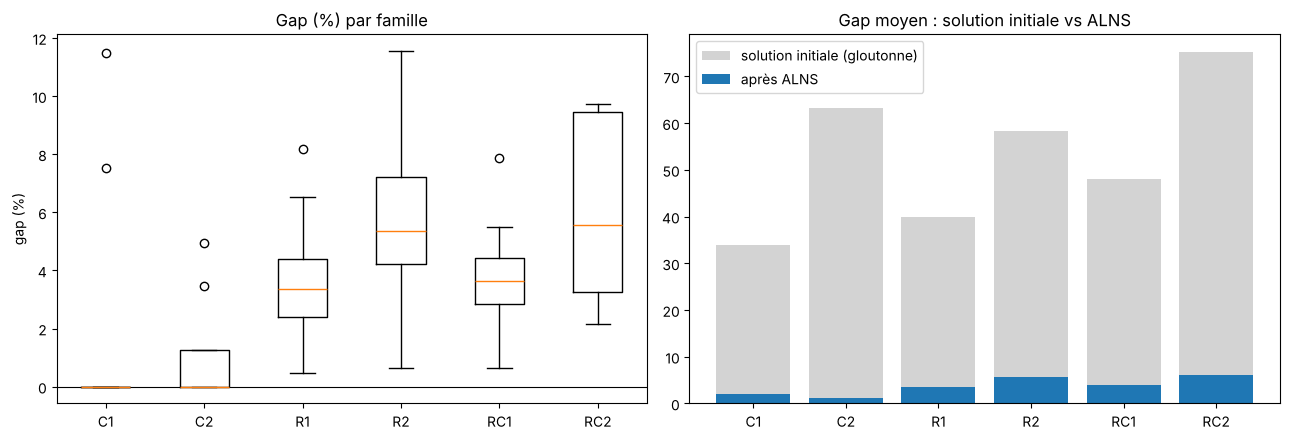

Kruskal-Wallis (gap ~ famille) : H = 19.61, p = 0.0015
Mann-Whitney série 1 vs série 2 : U = 301, p = 0.1399


In [15]:
fams = ["C1", "C2", "R1", "R2", "RC1", "RC2"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].boxplot([df_sol[df_sol.family == f].gap for f in fams])
axes[0].set_xticklabels(fams)
axes[0].axhline(0, color="k", lw=0.8)
axes[0].set_title("Gap (%) par famille")
axes[0].set_ylabel("gap (%)")
axes[1].bar(fams, [df_sol[df_sol.family == f].init_gap.mean() for f in fams], color="lightgray",
            label="solution initiale (gloutonne)")
axes[1].bar(fams, [df_sol[df_sol.family == f].gap.mean() for f in fams], color="tab:blue",
            label="après ALNS")
axes[1].set_title("Gap moyen : solution initiale vs ALNS")
axes[1].legend()
plt.tight_layout()
plt.show()

# La qualité dépend-elle de la famille d'instances ? (tests non paramétriques)
h, p = stats.kruskal(*[df_sol[df_sol.family == f].gap for f in fams])
print(f"Kruskal-Wallis (gap ~ famille) : H = {h:.2f}, p = {p:.4f}")
serie = df_sol.family.str[-1]
u, p2 = stats.mannwhitneyu(df_sol[serie == "1"].gap, df_sol[serie == "2"].gap)
print(f"Mann-Whitney série 1 vs série 2 : U = {u:.0f}, p = {p2:.4f}")

In [16]:
pd.set_option("display.max_rows", 60)
df_sol[["instance", "family", "cost", "bks", "gap", "vehicles", "bks_vehicles", "time"]].round(2)

,instance,family,cost,bks,gap,vehicles,bks_vehicles,time
0,C101,C1,827.3,827.3,0.00,10,10,12.63
1,C102,C1,827.3,827.3,0.00,10,10,13.62
2,C103,C1,826.3,826.3,0.00,10,10,13.41
3,C104,C1,884.7,822.9,7.51,10,10,13.86
4,C105,C1,827.3,827.3,0.00,10,10,13.01
5,C106,C1,827.3,827.3,0.00,10,10,13.70
6,C107,C1,827.3,827.3,0.00,10,10,13.23
7,C108,C1,827.3,827.3,0.00,10,10,14.43
8,C109,C1,922.3,827.3,11.48,10,10,13.63
9,C201,C2,589.1,589.1,-0.00,3,3,34.35


Analyse : sur les 56 instances, le gap moyen est de 3,82 % (intervalle de confiance à 95 % : [2,97 ; 4,67] %). La meilleure solution connue est retrouvée sur 12 instances, 39 instances sont sous 5 % et le gap maximal est de 11,54 % (R211). Le temps moyen est de 24 s par instance, environ 15 s sur la série 1 et 30 à 35 s sur la série 2, où les tournées sont plus longues et donc plus chères à simuler. Partant d'une solution initiale à 52 % en moyenne, l'ALNS divise l'écart par plus de dix.

La répartition des clients a un effet significatif (Kruskal-Wallis, p = 0,0015). Les instances groupées C sont les plus faciles (1,65 % en moyenne), devant les instances aléatoires R (4,63 %) et mixtes RC (4,95 %). Sur les instances C, l'algorithme trouve souvent l'optimum, mais il peut aussi rester bloqué : C104 et C109 finissent à 7,5 % et 11,5 %. La différence entre la série 1 et la série 2 (3,21 % contre 4,47 %) n'est pas significative (Mann-Whitney, p = 0,14).

Le nombre de camions est souvent différent de celui des BKS : il est égal sur 32 instances, plus petit sur 13 et plus grand sur 11. Sur la série 2, l'ALNS utilise moins de camions que les BKS (4,45 contre 5,45 en R2, 5,62 contre 6,25 en RC2). Comme notre objectif est la distance, utiliser moins de camions n'est pas un avantage ici : l'algorithme reste sur des tournées très longues parce qu'ouvrir une nouvelle tournée coûte toujours plus cher, localement, qu'insérer dans une tournée existante. Cela explique en partie les gaps plus élevés sur R2 et RC2.

<a id="section-6-3"></a>
### 6.3. Convergence
Gap de la meilleure solution au fil des itérations (3000 itérations, 3 graines). Cela permet de voir à partir de combien d'itérations le gain devient faible.

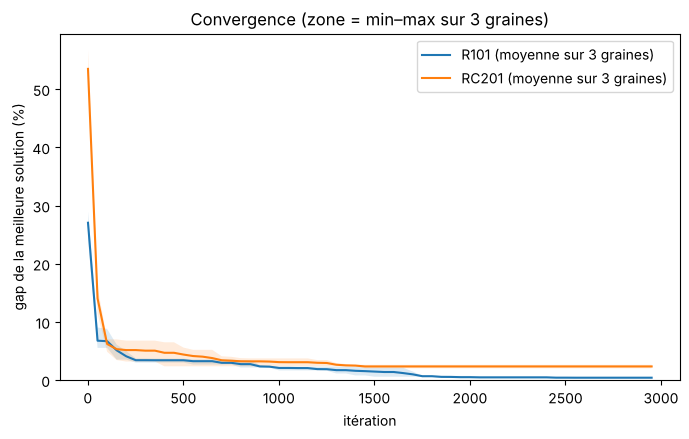

instance,R101,RC201
iteration,,
51,6.77,14.02
501,3.41,4.39
1001,2.09,3.09
2001,0.50,2.35
2951,0.41,2.35


In [17]:
def exp_convergence():
    rows = []
    for name in ["R101", "RC201"]:
        inst, bks = load_instance(name)
        d = build_data(inst)
        for seed in [1, 2, 3]:
            res = alns(d, iterations=3000, graine=seed)
            for it in range(0, 3000, 50):
                rows.append(dict(instance=name, seed=seed, iteration=it + 1,
                                 gap=100 * (res["hist_meilleur"][it] - bks["cost"]) / bks["cost"],
                                 time=res["temps"]))
    return pd.DataFrame(rows)


df_conv = cached("convergence", exp_convergence)
fig, ax = plt.subplots(figsize=(8, 4.5))
for name, grp in df_conv.groupby("instance"):
    s = grp.groupby("iteration").gap.agg(["mean", "min", "max"])
    ax.plot(s.index, s["mean"], label=f"{name} (moyenne sur 3 graines)")
    ax.fill_between(s.index, s["min"], s["max"], alpha=0.15)
ax.set_xlabel("itération")
ax.set_ylabel("gap de la meilleure solution (%)")
ax.set_title("Convergence (zone = min–max sur 3 graines)")
ax.set_ylim(bottom=0)
ax.legend()
plt.show()
df_conv[df_conv.iteration.isin([51, 501, 1001, 2001, 2951])].pivot_table(
    index="iteration", columns="instance", values="gap").round(2)

Analyse : le gap baisse vite au début puis de plus en plus lentement. Sur R101, il passe de 6,8 % après 50 itérations à 2,1 % après 1000 itérations, puis à 0,4 % après 3000 itérations. Sur RC201, il passe de 14,0 % à 3,1 % puis à 2,4 %, et ne bouge presque plus après 2000 itérations.

Les écarts entre graines sont faibles en fin de recherche : entre 0,35 % et 0,45 % pour R101 et entre 2,0 % et 2,6 % pour RC201 à 3000 itérations. L'algorithme est donc assez robuste au hasard. En revanche, le budget de 1000 itérations utilisé dans le reste de l'étude est un compromis : il garde des temps raisonnables, mais il laisse encore du gain possible, surtout sur les instances de type R. Les gaps de la section 6.2 sont donc une estimation pessimiste de ce que la méthode peut atteindre.

<a id="section-6-4"></a>
### 6.4. Passage à l'échelle
Instances générées aléatoirement (clients répartis uniformément, fenêtres de largeur 100) de 25 à 400 clients, 300 itérations. Il n'y a pas de BKS : nous mesurons le temps par itération et l'amélioration par rapport à la solution initiale. Un ajustement $t = a \cdot n^b$ donne la croissance du temps de calcul.

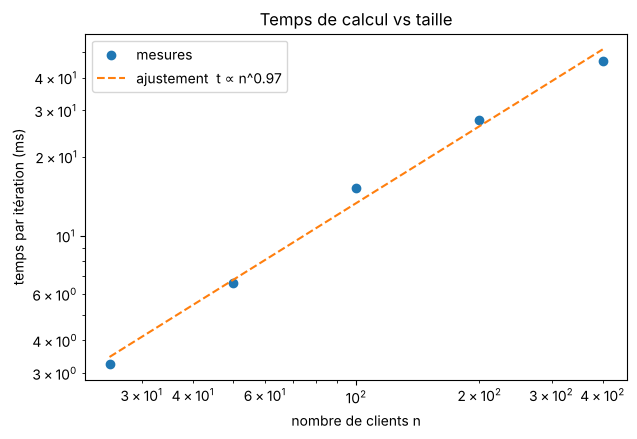

Exposant empirique : temps par itération ≈ n^0.97


,n,cost,init_cost,amelioration,vehicles,time,ms_par_iteration
0,25,1531.0,1970.6,22.31,4,0.97,3.24
1,50,2332.1,3183.3,26.74,7,1.99,6.63
2,100,3593.5,5119.4,29.81,9,4.57,15.23
3,200,5830.3,7853.1,25.76,17,8.25,27.51
4,400,10630.5,13839.9,23.19,35,13.87,46.23


In [18]:
def generate_instance(n, tw_width=100.0, capacity=200, seed=0, side=200.0):
    """Instance CVRPTW aléatoire : dépôt central, clients uniformes, fenêtres de largeur
    tw_width toutes atteignables depuis le dépôt."""
    rng = np.random.default_rng(seed)
    xy = rng.uniform(0, side, (n, 2))
    coords = np.vstack([[side / 2, side / 2], xy]).round(1)
    d0 = np.sqrt(((coords - coords[0]) ** 2).sum(1))
    horizon, service = 10 * side, 10
    e = rng.uniform(d0, horizon - d0 - service - tw_width)
    tw = np.column_stack([e, e + tw_width]).round()
    tw[0] = [0, horizon]
    demand = rng.integers(1, 30, n + 1)
    demand[0] = 0
    return dict(node_coord=coords, demand=demand, capacity=capacity, time_window=tw,
                service_time=service, vehicles=n // 5)


def exp_scaling():
    rows = []
    for n in [25, 50, 100, 200, 400]:
        d = build_data(generate_instance(n, seed=n))
        res = alns(d, iterations=300, graine=1)
        cost = check_solution(d, res["tournees"])
        rows.append(dict(n=n, cost=cost, init_cost=res["cout_initial"],
                         amelioration=100 * (res["cout_initial"] - cost) / res["cout_initial"],
                         vehicles=len(res["tournees"]), time=res["temps"],
                         ms_par_iteration=1000 * res["temps"] / 300))
    return pd.DataFrame(rows)


df_scal = cached("scaling", exp_scaling)
b, log_a = np.polyfit(np.log(df_scal.n), np.log(df_scal.ms_par_iteration), 1)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.loglog(df_scal.n, df_scal.ms_par_iteration, "o", label="mesures")
nn = np.linspace(25, 400, 50)
ax.loglog(nn, np.exp(log_a) * nn ** b, "--", label=f"ajustement  t ∝ n^{b:.2f}")
ax.set_xlabel("nombre de clients n")
ax.set_ylabel("temps par itération (ms)")
ax.set_title("Temps de calcul vs taille")
ax.legend()
plt.show()
print(f"Exposant empirique : temps par itération ≈ n^{b:.2f}")
df_scal.round(2)

Analyse : le temps par itération passe de 3,2 ms pour 25 clients à 46 ms pour 400 clients. L'ajustement donne un exposant de 0,97 : le coût d'une itération est presque proportionnel au nombre de clients. C'est mieux que la borne théorique de la section 4.5, car $q$ reste limité à 20 et la longueur des tournées est limitée par la capacité, donc seul le nombre de positions à tester augmente avec $n$.

L'amélioration par rapport à la solution initiale reste stable, entre 22 % et 30 %, quelle que soit la taille. Avec seulement 300 itérations, ces solutions ne sont certainement pas optimales, et nous n'avons pas de référence pour mesurer leur gap. Le temps de construction de la solution initiale augmente plus vite que celui des itérations, puisqu'elle insère les $n$ clients un par un en testant à chaque fois tous les clients restants. C'est ce qui limitera le passage à plusieurs milliers de clients (section 7).

<a id="section-6-5"></a>
### 6.5. Sensibilité aux paramètres
Nous changeons un seul paramètre à la fois par rapport au réglage par défaut ($q \in [5, 20]$, $T_0$ calibrée à 5 %, $\rho = 0.1$), sur une instance par famille (C103, C203, R103, R203, RC103, RC203), avec 1000 itérations et 2 graines. Chaque variante est comparée au réglage par défaut avec un test de Wilcoxon apparié (mêmes instances, mêmes graines).

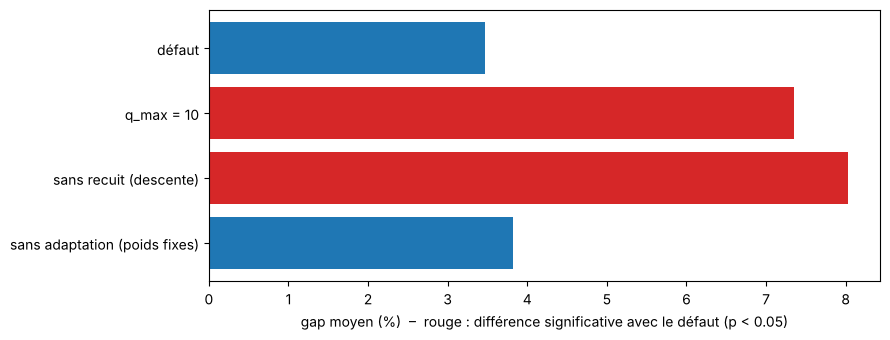

,gap_moyen,gap_max,temps,p_wilcoxon
config,,,,
défaut,3.467,9.733,25.235,NaN
q_max = 10,7.353,14.258,9.812,0.005
sans recuit (descente),8.030,30.236,25.165,0.027
sans adaptation (poids fixes),3.816,10.739,25.147,0.770


In [19]:
SENS_INST = ["C103", "C203", "R103", "R203", "RC103", "RC203"]
CONFIGS = {
    "défaut": {},
    "q_max = 10": dict(q_max=10),
    "sans recuit (descente)": dict(depart_pire=1e-9),
    "sans adaptation (poids fixes)": dict(reaction=0.0),
}


def exp_sensitivity():
    dfs = []
    for label, params in CONFIGS.items():
        dfs.append(run_benchmark(SENS_INST, seeds=[1, 2], iterations=1000, **params)
                   .assign(config=label))
    return pd.concat(dfs)


df_sens = cached("sensitivity", exp_sensitivity)
ref = df_sens[df_sens.config == "défaut"].set_index(["instance", "seed"]).gap
rows = []
for label in CONFIGS:
    g = df_sens[df_sens.config == label].set_index(["instance", "seed"]).gap.loc[ref.index]
    p = stats.wilcoxon(g, ref).pvalue if label != "défaut" and (g != ref).any() else np.nan
    rows.append(dict(config=label, gap_moyen=g.mean(), gap_max=g.max(),
                     temps=df_sens[df_sens.config == label].time.mean(), p_wilcoxon=p))
sens = pd.DataFrame(rows).set_index("config")
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.barh(sens.index[::-1], sens.gap_moyen[::-1],
        color=["tab:red" if p < 0.05 else "tab:blue" for p in sens.p_wilcoxon.fillna(1)[::-1]])
ax.set_xlabel("gap moyen (%)  –  rouge : différence significative avec le défaut (p < 0.05)")
plt.tight_layout()
plt.show()
sens.round(3)

Analyse : deux paramètres ont un effet net. Limiter la destruction à 10 clients au plus fait passer le gap moyen de 3,47 % à 7,35 % (Wilcoxon, p = 0,005). Les itérations sont plus rapides (10 s contre 25 s par instance), mais le voisinage est trop petit pour réorganiser des tournées soumises aux fenêtres de temps. Supprimer le recuit, c'est-à-dire n'accepter que des améliorations, fait passer le gap à 8,03 % (p = 0,027), avec un pire cas à 30 % : sans acceptation de solutions moins bonnes, la recherche reste bloquée dans le premier optimum local.

L'adaptation des poids n'a pas d'effet mesurable : 3,82 % avec des poids fixes contre 3,47 % (p = 0,77). Avec 1000 itérations, il n'y a que 10 mises à jour des poids, ce qui est peu, et nos trois méthodes de destruction donnent des résultats assez proches. Ce qui compte le plus ici, c'est la taille du voisinage et la diversification apportée par le recuit.

<a id="section-6-6"></a>
### 6.6. Rôle des opérateurs de destruction
Sur les 56 exécutions de la section 6.2, nous comparons la part des nouvelles meilleures solutions trouvées par chaque méthode de destruction à sa part d'utilisation. Une efficacité relative supérieure à 1 veut dire que la méthode trouve plus de records que la moyenne.

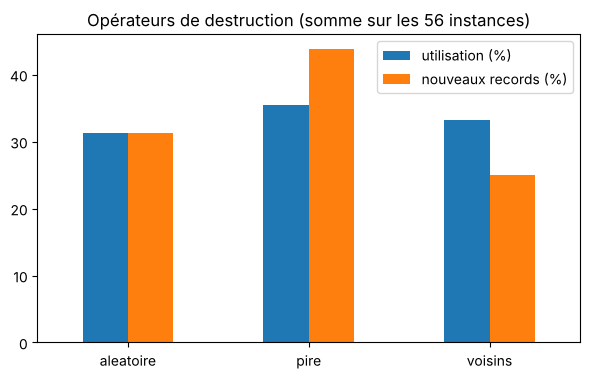

,utilisation (%),nouveaux records (%),efficacité relative
aleatoire,31.28,31.21,1.00
pire,35.52,43.80,1.23
voisins,33.20,24.99,0.75


In [20]:
best = np.array([df_sol[f"records_{o}"].sum() for o in NOMS_D], float)
use = np.array([df_sol[f"use_{o}"].sum() for o in NOMS_D], float)
op_df = pd.DataFrame({"utilisation (%)": 100 * use / use.sum(),
                      "nouveaux records (%)": 100 * best / best.sum()}, index=NOMS_D)
op_df["efficacité relative"] = op_df["nouveaux records (%)"] / op_df["utilisation (%)"]
op_df[["utilisation (%)", "nouveaux records (%)"]].plot.bar(figsize=(7, 4), rot=0)
plt.title(f"Opérateurs de destruction (somme sur les {len(df_sol)} instances)")
plt.show()
op_df.round(2)

Analyse : la destruction pire est la plus efficace. Elle représente 35,5 % des utilisations et 43,8 % des nouvelles meilleures solutions, soit une efficacité relative de 1,23. La destruction aléatoire est dans la moyenne (1,00). La destruction voisins est la moins efficace (0,75) : retirer des clients proches les uns des autres aide peu quand leurs fenêtres de temps sont très différentes, car ils ne peuvent pas être servis par la même tournée.

Les trois méthodes sont utilisées à peu près autant (entre 31 % et 36 %), ce qui rejoint le résultat de la section 6.5 : l'adaptation ne fait pas beaucoup bouger les poids.

<a id="section-6-7"></a>
### 6.7. Coût des fenêtres de temps
Nous résolvons les mêmes instances avec et sans fenêtres de temps (sans fenêtres, c'est un CVRP). L'écart montre ce que coûte, en distance et en camions, le fait de livrer dans un créneau.

In [21]:
TW_INST = ["C101", "C201", "R101", "R201", "RC101", "RC201"]
df_tw = cached("tw_impact", lambda: pd.concat([
    df_sol[df_sol.instance.isin(TW_INST)].assign(fenetres="avec"),     # déjà calculé en 6.2
    run_benchmark(TW_INST, seeds=[1], iterations=1000, relax=True).assign(fenetres="sans")]))
tw = df_tw.pivot_table(index="instance", columns="fenetres", values=["cost", "vehicles"])
tw[("surcoût distance (%)", "")] = 100 * (tw[("cost", "avec")] - tw[("cost", "sans")]) / tw[("cost", "sans")]
tw.round(2)

cost        vehicles       surcoût distance (%)
fenetres    avec   sans     avec  sans                     
instance                                                   
C101       827.3  929.4     10.0  10.0               -10.99
C201       589.1  578.6      3.0   3.0                 1.81
R101      1657.7  833.9     20.0   8.0                98.79
R201      1182.6  654.7      7.0   2.0                80.63
RC101     1661.9  984.1     16.0   9.0                68.88
RC201     1300.5  669.1      8.0   2.0                94.37

Analyse : les fenêtres de temps coûtent très cher sur les instances R et RC. Sans fenêtres, la distance baisse de 41 % à 50 %, ce qui veut dire que les fenêtres augmentent la distance de 69 % à 99 %. Le nombre de camions baisse aussi fortement : de 20 à 8 sur R101, de 7 à 2 sur R201. Sans fenêtres, seule la capacité limite les tournées. Sur les instances groupées C, l'effet est presque nul (+1,8 % sur C201) : les fenêtres y sont construites pour être compatibles avec un parcours naturel des groupes de clients.

C101 donne un résultat impossible : la solution sans fenêtres (929,4) est plus chère que la solution avec fenêtres (827,3), alors que toute solution qui respecte les fenêtres reste valable sans elles. L'ALNS n'a donc pas convergé sur cette version : sans fenêtres, beaucoup plus de positions d'insertion sont réalisables, l'espace de recherche est plus grand et 1000 itérations ne suffisent pas. La solution initiale y est aussi bien plus mauvaise (1158,6 contre 876,8), car la réparation gloutonne n'est plus guidée par les fenêtres. Ce cas montre que le budget doit être adapté à la taille de l'espace de recherche et pas seulement au nombre de clients.

<a id="section-7"></a>
## 7. Limites et axes d'amélioration

Temps de calcul. Notre code est écrit en Python simple : chaque test d'insertion resimule toute la tournée et la solution est copiée à chaque itération. Il faut 15 à 40 s pour 1000 itérations sur 100 clients. Le sujet demande de traiter plusieurs milliers de clients, ce que cette version ne permet pas : la construction de la solution initiale devient trop longue. Plusieurs améliorations sont possibles :
* tester une insertion en $O(1)$ au lieu de $O(|r|)$, en gardant pour chaque position l'heure d'arrivée au plus tôt et l'heure de départ au plus tard (Savelsbergh, 1992) ;
* garder en mémoire les coûts d'insertion et ne recalculer que la tournée modifiée ;
* compiler le cœur du calcul avec Numba. Une première version de notre projet utilisait ces trois idées et était environ 100 fois plus rapide, avec un gap moyen de 1,1 % sur Solomon et des instances jusqu'à 3000 clients.

Budget d'itérations. Avec 1000 itérations, le gap moyen est de 3,82 %. La section 6.3 montre qu'on descend à 0,4 % sur R101 avec 3000 itérations. Un code plus rapide permettrait d'augmenter le budget sans allonger le temps de calcul.

Nombre de camions. Ouvrir une nouvelle tournée n'est presque jamais choisi, car c'est localement plus cher que d'insérer dans une tournée existante. Sur la série 2, l'algorithme reste avec moins de camions que les BKS et des tournées trop longues. On pourrait ajouter une destruction qui vide une tournée entière, ou forcer de temps en temps l'ouverture d'une tournée.

Pièges locaux. Sur C104 et C109, l'algorithme reste bloqué à 7,5 % et 11,5 % alors qu'il trouve l'optimum sur la plupart des autres instances C. Une destruction plus forte de temps en temps, ou un redémarrage depuis la meilleure solution, pourrait aider.

Adaptation des poids. Elle n'apporte rien de mesurable avec notre budget. Soit on la garde en ajoutant des méthodes plus différentes les unes des autres, soit on peut la retirer pour simplifier.

Robustesse. Sur Solomon, chaque instance n'a été lancée qu'avec une seule graine à cause du temps de calcul. La section 6.3 montre de faibles écarts entre graines, mais il faudrait plusieurs graines sur toutes les instances pour mesurer la variance correctement.

Modèle. Nous considérons que le temps de trajet est égal à la distance. Le sujet parle du trafic selon les tranches horaires : il faudrait des temps de trajet qui dépendent de l'heure de départ. La simulation de tournée s'adapte facilement à ce cas, contrairement au test en $O(1)$.

Comparaison. Nous n'avons pas comparé l'ALNS à une méthode à population. Les meilleurs résultats actuels sur Solomon sont obtenus par un algorithme génétique hybride (HGS, Vidal et al., 2013), à environ 0,1 % des BKS.

<a id="section-8"></a>
## 8. Conclusion

Nous avons traité le niveau A du projet, le CVRPTW. Nous avons montré que le problème est NP-difficile par réduction au TSP, puis écrit un PLNE à deux indices avec des contraintes MTZ et des contraintes de temps de type Big-M. Résolu avec HiGHS, ce PLNE donne l'optimum sur des sous-instances de 50 clients, mais son temps de résolution augmente très vite avec la taille.

Pour les instances complètes, nous avons implémenté une ALNS avec acceptation par recuit simulé : trois méthodes de destruction, deux méthodes de réparation et un choix adaptatif des méthodes. Le code reste simple et lisible, et un vérificateur indépendant contrôle toutes les solutions.

L'étude expérimentale donne les résultats suivants :
* l'ALNS retrouve l'optimum du PLNE sur 16 sous-instances sur 18, avec un écart maximal de 0,40 % ;
* sur les 56 instances de Solomon, le gap moyen est de 3,82 %, l'optimum connu est retrouvé 12 fois et le gap maximal est de 11,54 %, avec 24 s en moyenne par instance ;
* les instances groupées sont nettement plus faciles que les instances aléatoires ou mixtes ;
* la taille du voisinage et le recuit simulé sont les deux éléments essentiels de la méthode, alors que l'adaptation des poids a peu d'effet ;
* le temps par itération augmente presque linéairement avec le nombre de clients ;
* les fenêtres de temps peuvent presque doubler la distance parcourue sur des clients dispersés.

La principale limite est le temps de calcul, qui empêche de traiter plusieurs milliers de clients et d'augmenter le budget d'itérations. Les améliorations proposées en section 7, en particulier le test d'insertion en temps constant et la compilation, permettraient de garder la même méthode tout en atteignant ces tailles et en réduisant le gap.

<a id="section-9"></a>
## 9. Références
* Dantzig, G. B., & Ramser, J. H. (1959). The truck dispatching problem. *Management Science*, 6(1), 80–91.
* Karp, R. M. (1972). Reducibility among combinatorial problems. In *Complexity of Computer Computations*, 85–103.
* Kirkpatrick, S., Gelatt, C. D., & Vecchi, M. P. (1983). Optimization by simulated annealing. *Science*, 220(4598), 671–680.
* Miller, C. E., Tucker, A. W., & Zemlin, R. A. (1960). Integer programming formulation of traveling salesman problems. *Journal of the ACM*, 7(4), 326–329.
* Pisinger, D., & Ropke, S. (2007). A general heuristic for vehicle routing problems. *Computers & Operations Research*, 34(8), 2403–2435.
* Ropke, S., & Pisinger, D. (2006). An adaptive large neighborhood search heuristic for the pickup and delivery problem with time windows. *Transportation Science*, 40(4), 455–472.
* Savelsbergh, M. W. P. (1992). The vehicle routing problem with time windows: minimizing route duration. *ORSA Journal on Computing*, 4(2), 146–154.
* Shaw, P. (1998). Using constraint programming and local search methods to solve vehicle routing problems. *CP-98*, LNCS 1520, 417–431.
* Solomon, M. M. (1987). Algorithms for the vehicle routing and scheduling problems with time window constraints. *Operations Research*, 35(2), 254–265.
* Toth, P., & Vigo, D. (Eds.). (2014). *Vehicle Routing: Problems, Methods, and Applications* (2nd ed.). SIAM.
* Vidal, T., Crainic, T. G., Gendreau, M., & Prins, C. (2013). A hybrid genetic algorithm with adaptive diversity management for a large class of vehicle routing problems with time-windows. *Computers & Operations Research*, 40(1), 475–489.
* Bibliothèque `vrplib` et instances : https://github.com/PyVRP/VRPLIB, https://github.com/PyVRP/Instances